In [4]:
#Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV

# For evaluating Regression models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# For Random Forest (Grid Search)
from sklearn.ensemble import RandomForestRegressor

#For XGBoost (Random Search)
from xgboost import XGBRegressor

# Standard seed used throughout the notebook for reproducibility
SEED = 1

In [5]:
from pathlib import Path

csv_path = Path(r'C:\Users\Lenovo\OneDrive\Dokumente\New learning\Ironhack\Final project\clean_employee_data.csv')
if not csv_path.exists():
    raise FileNotFoundError(f'File not found: {csv_path}')

employee_df = pd.read_csv(csv_path)
employee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   int64
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   int64
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   int64
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   int64
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int64
 13  JobRole                   1470 non-null   int64
 14  JobSatisfaction           1470 non-null 

In [7]:
file_path = r'C:\Users\Lenovo\OneDrive\Dokumente\New learning\Ironhack\Final project\clean_employee_data.csv'
employee_df = pd.read_csv(file_path)
employee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   int64
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   int64
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   int64
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   int64
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int64
 13  JobRole                   1470 non-null   int64
 14  JobSatisfaction           1470 non-null 

In [ ]:
#Job Satisfaction
plt.figure(figsize=(8, 5))

sns.countplot(
    data=employee_df,
    x="JobSatisfaction",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Satisfaction")
plt.xlabel("Job Satisfaction (1 = Low, 4 = Very High)")
plt.ylabel("Number of Employees")

plt.show()

In [ ]:
#Distance From Home
plt.figure(figsize=(9, 5))

sns.histplot(
    data=employee_df,
    x="DistanceFromHome",
    hue="Attrition",
    kde=True,
    bins=15
)

plt.title("Distance From Home by Attrition")
plt.xlabel("Distance From Home")
plt.ylabel("Number of Employees")

plt.show()

In [ ]:
#Job Level
plt.figure(figsize=(8, 5))

sns.countplot(
    data=employee_df,
    x="JobLevel",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Number of Employees")

plt.show()

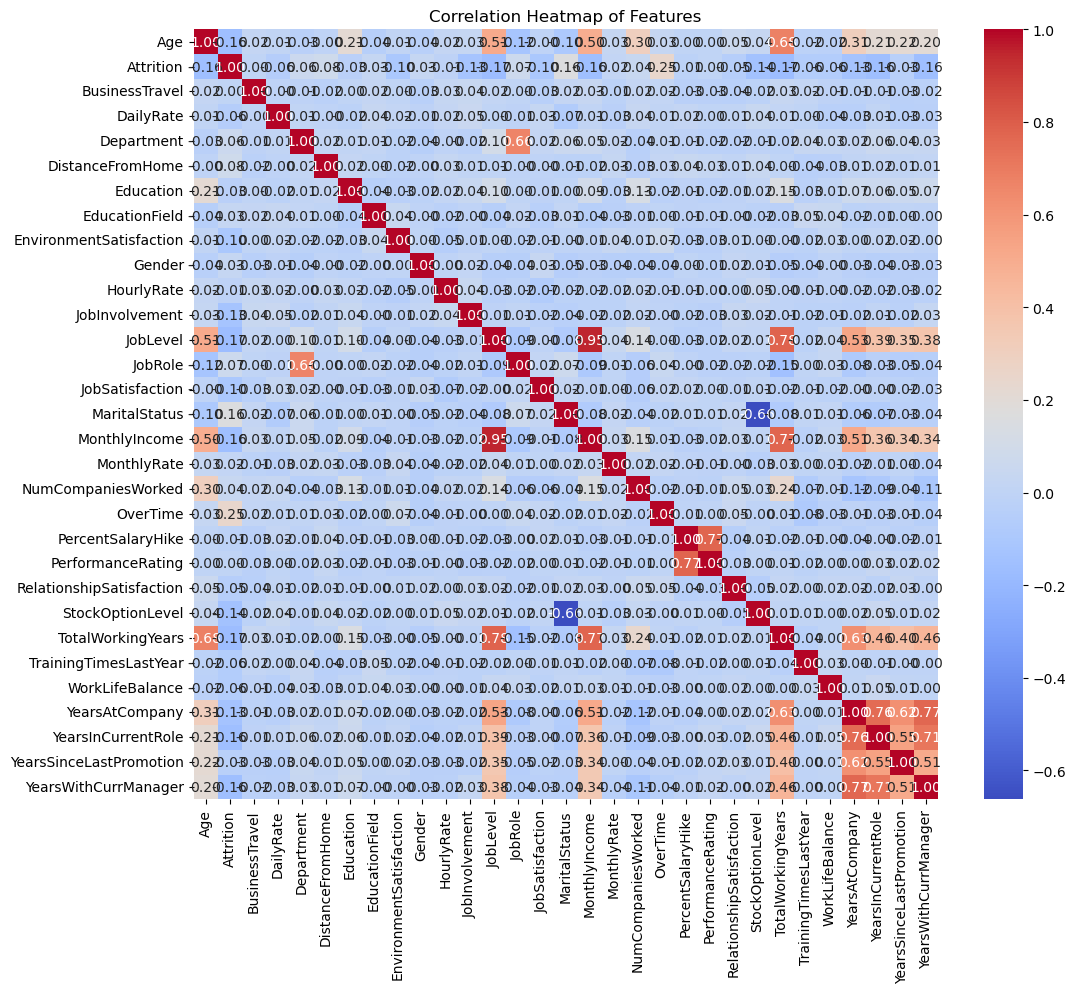

In [9]:
#Correlation analysis
full_corr = employee_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(full_corr, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Heatmap of Features')
plt.show()